# 01 — Data audit (T1b)

NASA C-MAPSS **FD001**: 1 operating condition, 1 fault mode (HPC degradation).

Exploratory statistics that inform design decisions are computed on the **training engines only** (from `data/splits/fd001_split.json`). The test files are only checked for structure (sequence lengths); test RUL labels are not inspected here.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import data

FIG = ROOT / 'results' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
cfg = data.load_config(ROOT / 'configs' / 'data_fd001.json')
split = data.load_config(ROOT / cfg['split_file'])

train_full = data.load_raw('FD001', 'train')
test_raw = data.load_raw('FD001', 'test')
train = train_full[train_full['unit'].isin(split['train_units'])]
print('train file rows:', train_full.shape, '| engines:', train_full.unit.nunique())
print('test file rows: ', test_raw.shape, '| engines:', test_raw.unit.nunique())
print('training-split engines:', train.unit.nunique(), '| validation engines:', len(split['val_units']))

train file rows: (20631, 26) | engines: 100
test file rows:  (13096, 26) | engines: 100
training-split engines: 80 | validation engines: 20


## Missing values and duplicates

In [2]:
print('Missing values (train file):', int(train_full.isna().sum().sum()))
print('Missing values (test file): ', int(test_raw.isna().sum().sum()))
print('Duplicate rows (train file):', int(train_full.duplicated().sum()))
print('Duplicate (unit, cycle) keys:', int(train_full.duplicated(['unit', 'cycle']).sum()))
gaps = train_full.groupby('unit')['cycle'].apply(lambda c: (c.diff().dropna() != 1).sum()).sum()
print('Non-consecutive cycle steps:', int(gaps))

Missing values (train file): 0
Missing values (test file):  0
Duplicate rows (train file): 0
Duplicate (unit, cycle) keys: 0
Non-consecutive cycle steps: 0


## Constant and near-constant channels

FD001 has one operating condition, so several channels never change. A channel with ≤ 2 distinct values in the training split carries no degradation signal and is dropped (rule `min_unique = 2` in the config).

In [3]:
chan = data.SETTINGS + data.SENSORS
summary = pd.DataFrame({'n_unique': train[chan].nunique(), 'std': train[chan].std()})
summary['kept'] = summary.index.isin(data.select_features(train, cfg['min_unique']))
summary

,n_unique,std,kept
setting1,154,2.186052e-03,False
setting2,13,2.924414e-04,False
setting3,1,0.000000e+00,False
s1,1,0.000000e+00,False
s2,304,5.000962e-01,True
s3,2922,6.121280e+00,True
s4,3894,8.988672e+00,True
s5,1,3.552820e-15,False
s6,2,1.390649e-03,False
s7,509,8.880222e-01,True


## Figure 1 — Engine lifetimes

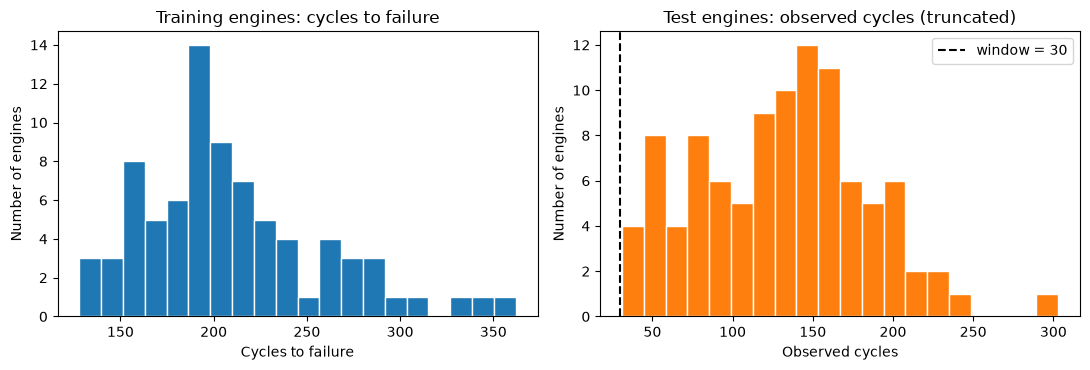

Lifetime min/median/max: 128 199.0 362
Shortest test sequence: 31


In [4]:
life = train.groupby('unit')['cycle'].max()
test_len = test_raw.groupby('unit')['cycle'].max()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(life, bins=20, color='tab:blue', edgecolor='white')
ax[0].set(title='Training engines: cycles to failure', xlabel='Cycles to failure', ylabel='Number of engines')
ax[1].hist(test_len, bins=20, color='tab:orange', edgecolor='white')
ax[1].axvline(cfg['window'], color='k', ls='--', label=f"window = {cfg['window']}")
ax[1].set(title='Test engines: observed cycles (truncated)', xlabel='Observed cycles', ylabel='Number of engines')
ax[1].legend()
fig.tight_layout(); fig.savefig(FIG / 'fig01_lifetimes.png', dpi=150); plt.show()
print('Lifetime min/median/max:', life.min(), life.median(), life.max())
print('Shortest test sequence:', test_len.min())

**Design impact.** Lifetimes vary by a factor of almost three, so cycle count alone is a poor predictor of RUL. The model must read degradation from the sensors. The shortest test engine has 31 observed cycles, so a **30-cycle window** fits every test engine without padding.

## Figure 2 — Sensor trajectories approaching failure

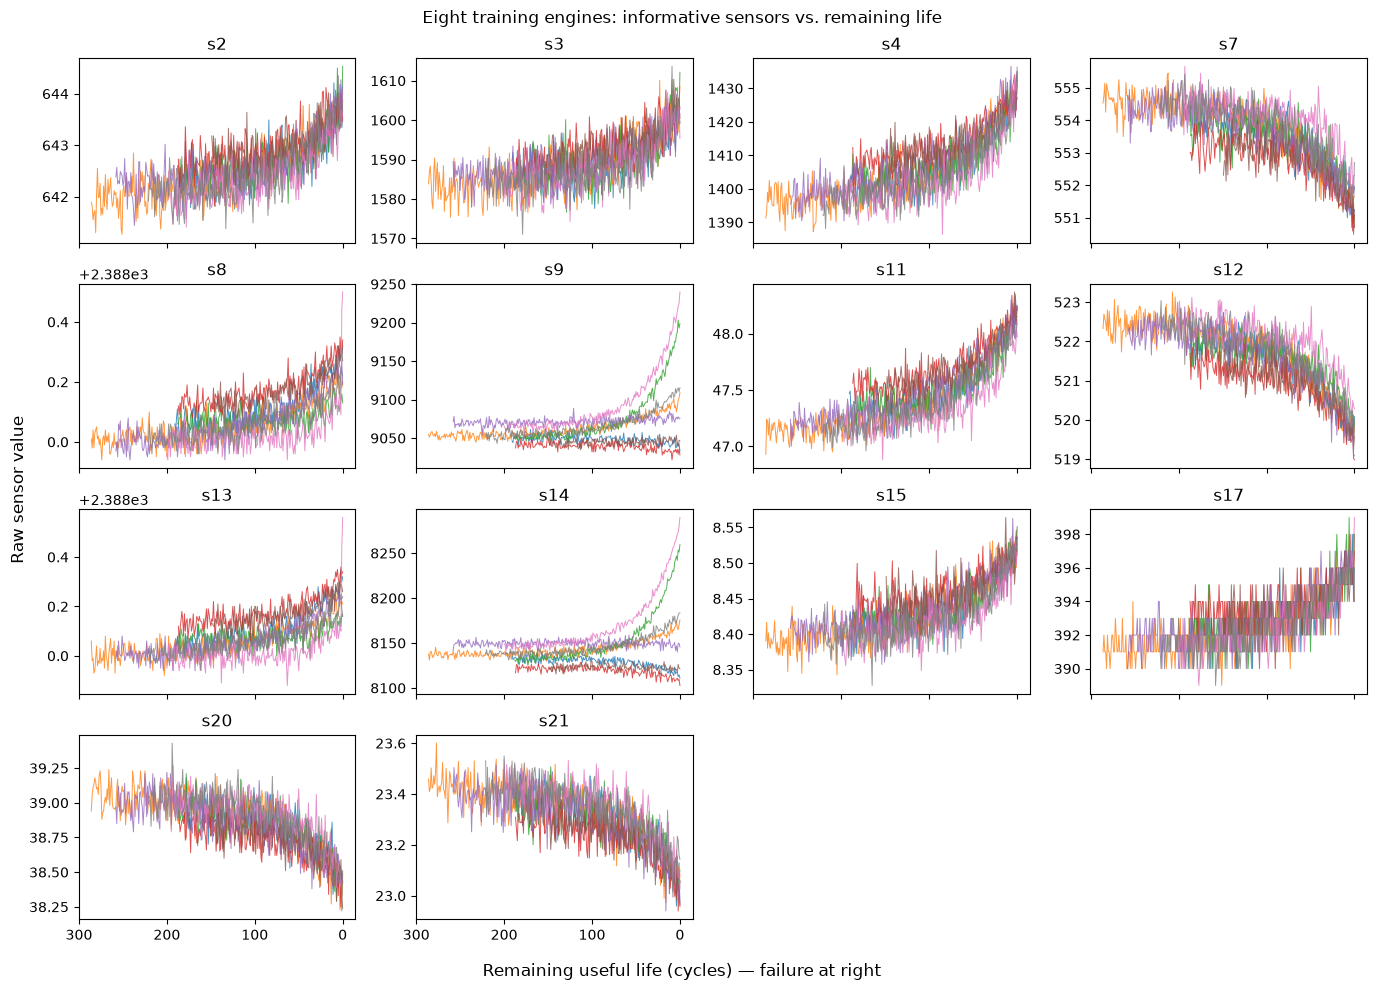

In [5]:
feats = data.select_features(train, cfg['min_unique'])
lab = data.add_train_rul(train, cap=10**6)
fig, axes = plt.subplots(4, 4, figsize=(14, 10), sharex=True)
for ax, s in zip(axes.flat, feats):
    for u in split['train_units'][:8]:
        g = lab[lab.unit == u]
        ax.plot(g['rul'], g[s], lw=0.7, alpha=0.8)
    ax.set_title(s)
for ax in axes.flat[len(feats):]: ax.axis('off')
axes[0, 0].invert_xaxis()  # shared x-axis: invert once
fig.supxlabel('Remaining useful life (cycles) — failure at right'); fig.supylabel('Raw sensor value')
fig.suptitle('Eight training engines: informative sensors vs. remaining life')
fig.tight_layout(); fig.savefig(FIG / 'fig02_sensor_trends.png', dpi=150); plt.show()

**Design impact.** Most sensors drift slowly early in life and change faster over the last ~100 cycles. s9 and s14 (core/fan speed related) behave differently: their direction differs between engines, so their information is engine-specific. This motivates the **piecewise-linear RUL cap (125)**: very early cycles look healthy, so their exact RUL is hard to infer. Readings are noisy from cycle to cycle, so a **window of recent cycles** should carry more information than a single cycle, which is the hypothesis the MLP-vs-RNN comparison tests. Some sensors rise and others fall, and their scales differ by orders of magnitude, so we need **per-feature min-max scaling fitted on training engines**.

## Figure 3 — Correlation of each sensor with RUL (training engines)

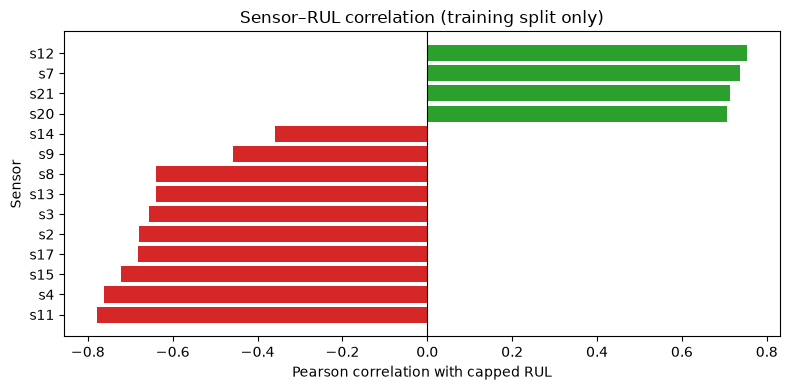

s11   -0.779
s4    -0.761
s15   -0.722
s17   -0.682
s2    -0.680
s3    -0.655
s13   -0.640
s8    -0.638
s9    -0.457
s14   -0.358
s20    0.706
s21    0.712
s7     0.737
s12    0.754
Name: rul, dtype: float64

In [6]:
corr = data.add_train_rul(train, cfg['rul_cap'])[feats + ['rul']].corr()['rul'].drop('rul').sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(corr.index, corr.values, color=['tab:red' if v < 0 else 'tab:green' for v in corr.values])
ax.set(xlabel='Pearson correlation with capped RUL', ylabel='Sensor', title='Sensor–RUL correlation (training split only)')
ax.axvline(0, color='k', lw=0.8)
fig.tight_layout(); fig.savefig(FIG / 'fig03_rul_correlation.png', dpi=150); plt.show()
corr.round(3)

**Design impact.** Every retained sensor has a non-trivial linear relationship with RUL, supporting the 14-feature set. Several pairs (e.g. s9/s14) are strongly related to each other, so a linear baseline may be unstable, which is a point for the T3a discussion.

## Figure 4 — Target definition: uncapped vs capped RUL

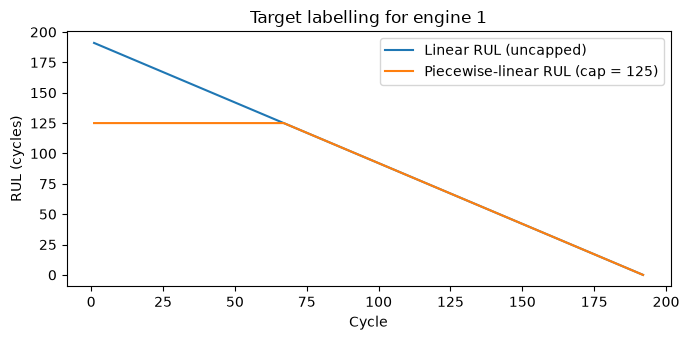

In [7]:
g = train[train.unit == split['train_units'][0]]
raw = data.add_train_rul(g, cap=10**6)['rul']; capped = data.add_train_rul(g, cfg['rul_cap'])['rul']
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(g['cycle'], raw, label='Linear RUL (uncapped)')
ax.plot(g['cycle'], capped, label=f"Piecewise-linear RUL (cap = {cfg['rul_cap']})")
ax.set(xlabel='Cycle', ylabel='RUL (cycles)', title=f"Target labelling for engine {split['train_units'][0]}")
ax.legend()
fig.tight_layout(); fig.savefig(FIG / 'fig04_rul_target.png', dpi=150); plt.show()

## Target imbalance after windowing

Training windows: 14459;  share at cap (125): 31.4%


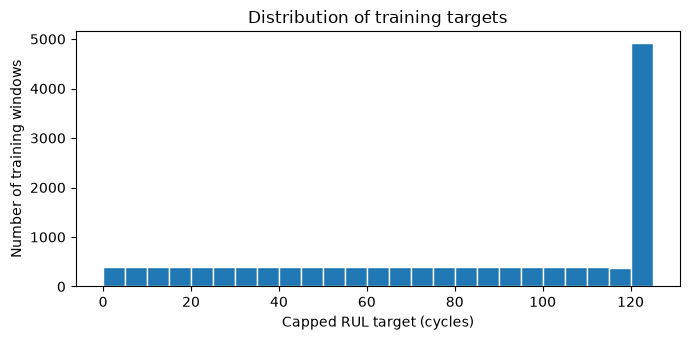

In [8]:
prep = data.load_prepared(cfg)
y = prep['train'][1]
print(f"Training windows: {len(y)};  share at cap ({cfg['rul_cap']}): {np.mean(y == cfg['rul_cap']):.1%}")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(y, bins=25, color='tab:blue', edgecolor='white')
ax.set(xlabel='Capped RUL target (cycles)', ylabel='Number of training windows', title='Distribution of training targets')
fig.tight_layout(); fig.savefig(FIG / 'fig05_target_distribution.png', dpi=150); plt.show()

**Design impact.** A large share of windows sit at the cap. A model could score reasonably by predicting "healthy" often, so the evaluation should also report error on the **low-RUL region** that matters for maintenance decisions, and the asymmetric NASA score should penalise late predictions.

## Leakage controls (T1c summary)

| Risk | Control |
|---|---|
| Overlapping windows from one engine in train and validation | Split by **engine unit** (`split_units`), saved to `data/splits/fd001_split.json` |
| Scaler / feature choice informed by validation or test data | `select_features` and `fit_scaler` see training engines only; saved to `models/preprocess_fd001.json` |
| Target leakage via `cycle` / total lifetime | `cycle` is not a model input; RUL is computed from lifetime only as a label |
| Test labels shaping design | `RUL_FD001.txt` is loaded only for final evaluation; this audit does not inspect it |
| Augmentation leaking into evaluation | Any noise augmentation (if used) is applied inside the training loop only |